Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).

The classes are ordered and not balanced (e.g. there are many more normal wines than excellent or poor ones). Outlier detection algorithms could be used to detect the few excellent or poor wines. Also, we are not sure if all input variables are relevant. So it could be interesting to test feature selection methods.

In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import math
import matplotlib.text as plttxt

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
wine_quality = fetch_ucirepo(id=186)

# data (as pandas dataframes)
X = wine_quality.data.features
y = wine_quality.data.targets

# metadata
print(wine_quality.metadata)

# variable information
print(wine_quality.variables)

df = pd.DataFrame(X)

{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

## Step 2: Inspect both datasets: check their shapes, columns, data types, missing values, duplicates, and quality score ranges.

In [4]:
# Combine physicochemical features and quality for the audit
data = pd.concat([X, y], axis=1)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Combined shape:", data.shape)
print("\nData types:\n", data.dtypes)
print("\nMissing values by column:\n", data.isna().sum())
print("\nDuplicate rows, including quality:", data.duplicated().sum())

quality_col = y.columns[0]
print(f"\nQuality range: {y[quality_col].min()} to {y[quality_col].max()}")
print("\nQuality score counts:\n", y[quality_col].value_counts().sort_index())

# Check whether the repository exposes wine color in its original table
original = getattr(wine_quality.data, "original", None)

if isinstance(original, pd.DataFrame) and "color" in original.columns:
    print("\nWine type counts:\n", original["color"].value_counts(dropna=False))
else:
    print("\nWine color is not available in the original table.")

Feature shape: (6497, 11)
Target shape: (6497, 1)
Combined shape: (6497, 12)

Data types:
 fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values by column:
 fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows, including quality: 1179

Quality range: 3 to 9

Quality score counts:
 quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9 

In [5]:
print("Missing values in combined data:", data.isna().sum().sum())
print("Duplicate rows, including quality:", data.duplicated().sum())
print("\nQuality score counts:")
print(y[quality_col].value_counts().sort_index().to_string())

Missing values in combined data: 0
Duplicate rows, including quality: 1179

Quality score counts:
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5


## Step 2: Clarify the target and inputs

The target is `quality`. The 11 physicochemical measurements in `X` are the model features. Add the `color` field from the original table so red and white wines remain distinguishable in the combined dataset. Keep a full copy and a separate exact-deduplicated copy for later comparison.

In [6]:
original = wine_quality.data.original
quality_col = y.columns[0]
feature_cols = list(X.columns)

# Verify that the color labels come from the same source rows as X and y.
assert len(X) == len(y) == len(original), 'Feature, target, and source row counts differ.'
assert 'color' in original.columns, 'The original table has no color column.'
if quality_col in original.columns:
    assert original[quality_col].reset_index(drop=True).equals(y[quality_col].reset_index(drop=True)), 'Original quality values do not align with y.'

# Keep all rows and add the target and wine type.
wine_data_all = X.reset_index(drop=True).copy()
wine_data_all[quality_col] = y[quality_col].reset_index(drop=True)
wine_data_all['color'] = original['color'].reset_index(drop=True)

# Model inputs are the physicochemical measurements plus wine type; quality is the target.
X_model = wine_data_all[feature_cols + ['color']]
y_model = wine_data_all[quality_col]

# Preserve red and white subsets for separate-model comparisons later.
red_wines = wine_data_all.loc[wine_data_all['color'].eq('red')].copy()
white_wines = wine_data_all.loc[wine_data_all['color'].eq('white')].copy()

# Keep the original rows and make a separate exact-deduplicated comparison copy.
wine_data_unique = wine_data_all.drop_duplicates().reset_index(drop=True)

print('Target:', quality_col)
print('Physicochemical features:', feature_cols)
print('Model input columns:', list(X_model.columns))
print('Target shape:', y_model.shape)
print('Rows by wine type:', wine_data_all['color'].value_counts().to_dict())
print('Rows before duplicate removal:', len(wine_data_all))
print('Exact duplicates including color:', wine_data_all.duplicated().sum())
print('Rows in unique comparison copy:', len(wine_data_unique))
print('Red subset shape:', red_wines.shape)
print('White subset shape:', white_wines.shape)

Target: quality
Physicochemical features: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Model input columns: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'color']
Target shape: (6497,)
Rows by wine type: {'white': 4898, 'red': 1599}
Rows before duplicate removal: 6497
Exact duplicates including color: 1177
Rows in unique comparison copy: 5320
Red subset shape: (1599, 13)
White subset shape: (4898, 13)


## Step 3: Explore the data

Explore the target distribution, compare red and white wines, and inspect physicochemical feature distributions and their rank correlations with quality. These summaries can reveal patterns and questions for later analysis; correlations alone do not establish cause and effect.

In [7]:
# Quality score distribution overall and for each wine type.
print('Quality counts overall:')
display(wine_data_all[quality_col].value_counts().sort_index().rename('count').to_frame())

print('Quality summary by wine type:')
display(wine_data_all.groupby('color')[quality_col].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2))

print('Quality counts by wine type:')
display(pd.crosstab(wine_data_all[quality_col], wine_data_all['color']).reindex(columns=['red', 'white'], fill_value=0))

# Inspect feature scale, spread, and skew to guide later preprocessing and modeling choices.
feature_summary = wine_data_all[feature_cols].describe().T
feature_summary['skew'] = wine_data_all[feature_cols].skew()
print('Physicochemical feature summary:')
display(feature_summary.round(3))

# Spearman correlation is used because quality is an ordered score.
spearman_by_color = {}
for color in ['red', 'white']:
    subset = wine_data_all.loc[wine_data_all['color'].eq(color), feature_cols + [quality_col]]
    spearman_by_color[color] = subset.corr(method='spearman')[quality_col].drop(quality_col)

spearman_results = pd.DataFrame({
    'all_wines': wine_data_all[feature_cols + [quality_col]].corr(method='spearman')[quality_col].drop(quality_col),
    'red': spearman_by_color['red'],
    'white': spearman_by_color['white'],
})
spearman_results = spearman_results.loc[spearman_results['all_wines'].abs().sort_values(ascending=False).index]
print('Spearman correlations between features and quality (descriptive, not causal):')
display(spearman_results.round(3))

Quality counts overall:


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


Quality summary by wine type:


,count,mean,median,std,min,max
color,,,,,,
red,1599,5.64,6.0,0.81,3,8
white,4898,5.88,6.0,0.89,3,9


Quality counts by wine type:


color,red,white
quality,,
3,10,20
4,53,163
5,681,1457
6,638,2198
7,199,880
8,18,175
9,0,5


Physicochemical feature summary:


,count,mean,std,min,25%,50%,75%,max,skew
fixed_acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900,1.723
volatile_acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580,1.495
citric_acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660,0.472
residual_sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800,1.435
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611,5.400
free_sulfur_dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000,1.220
total_sulfur_dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000,-0.001
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039,0.504
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010,0.387
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000,1.797


Spearman correlations between features and quality (descriptive, not causal):


,all_wines,red,white
alcohol,0.447,0.479,0.440
density,-0.323,-0.177,-0.348
chlorides,-0.295,-0.190,-0.314
volatile_acidity,-0.258,-0.381,-0.197
citric_acid,0.106,0.213,0.018
fixed_acidity,-0.098,0.114,-0.084
free_sulfur_dioxide,0.087,-0.057,0.024
total_sulfur_dioxide,-0.055,-0.197,-0.197
pH,0.033,-0.044,0.109
sulphates,0.030,0.377,0.033


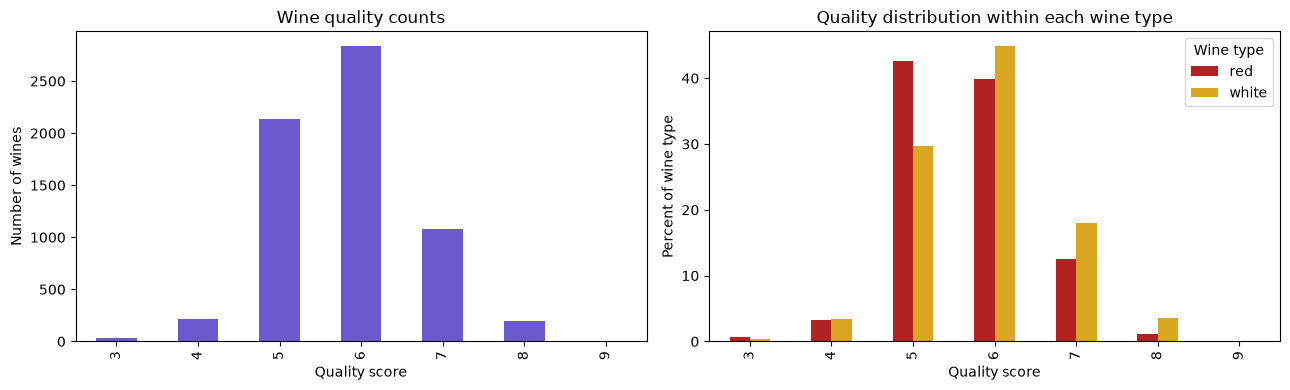

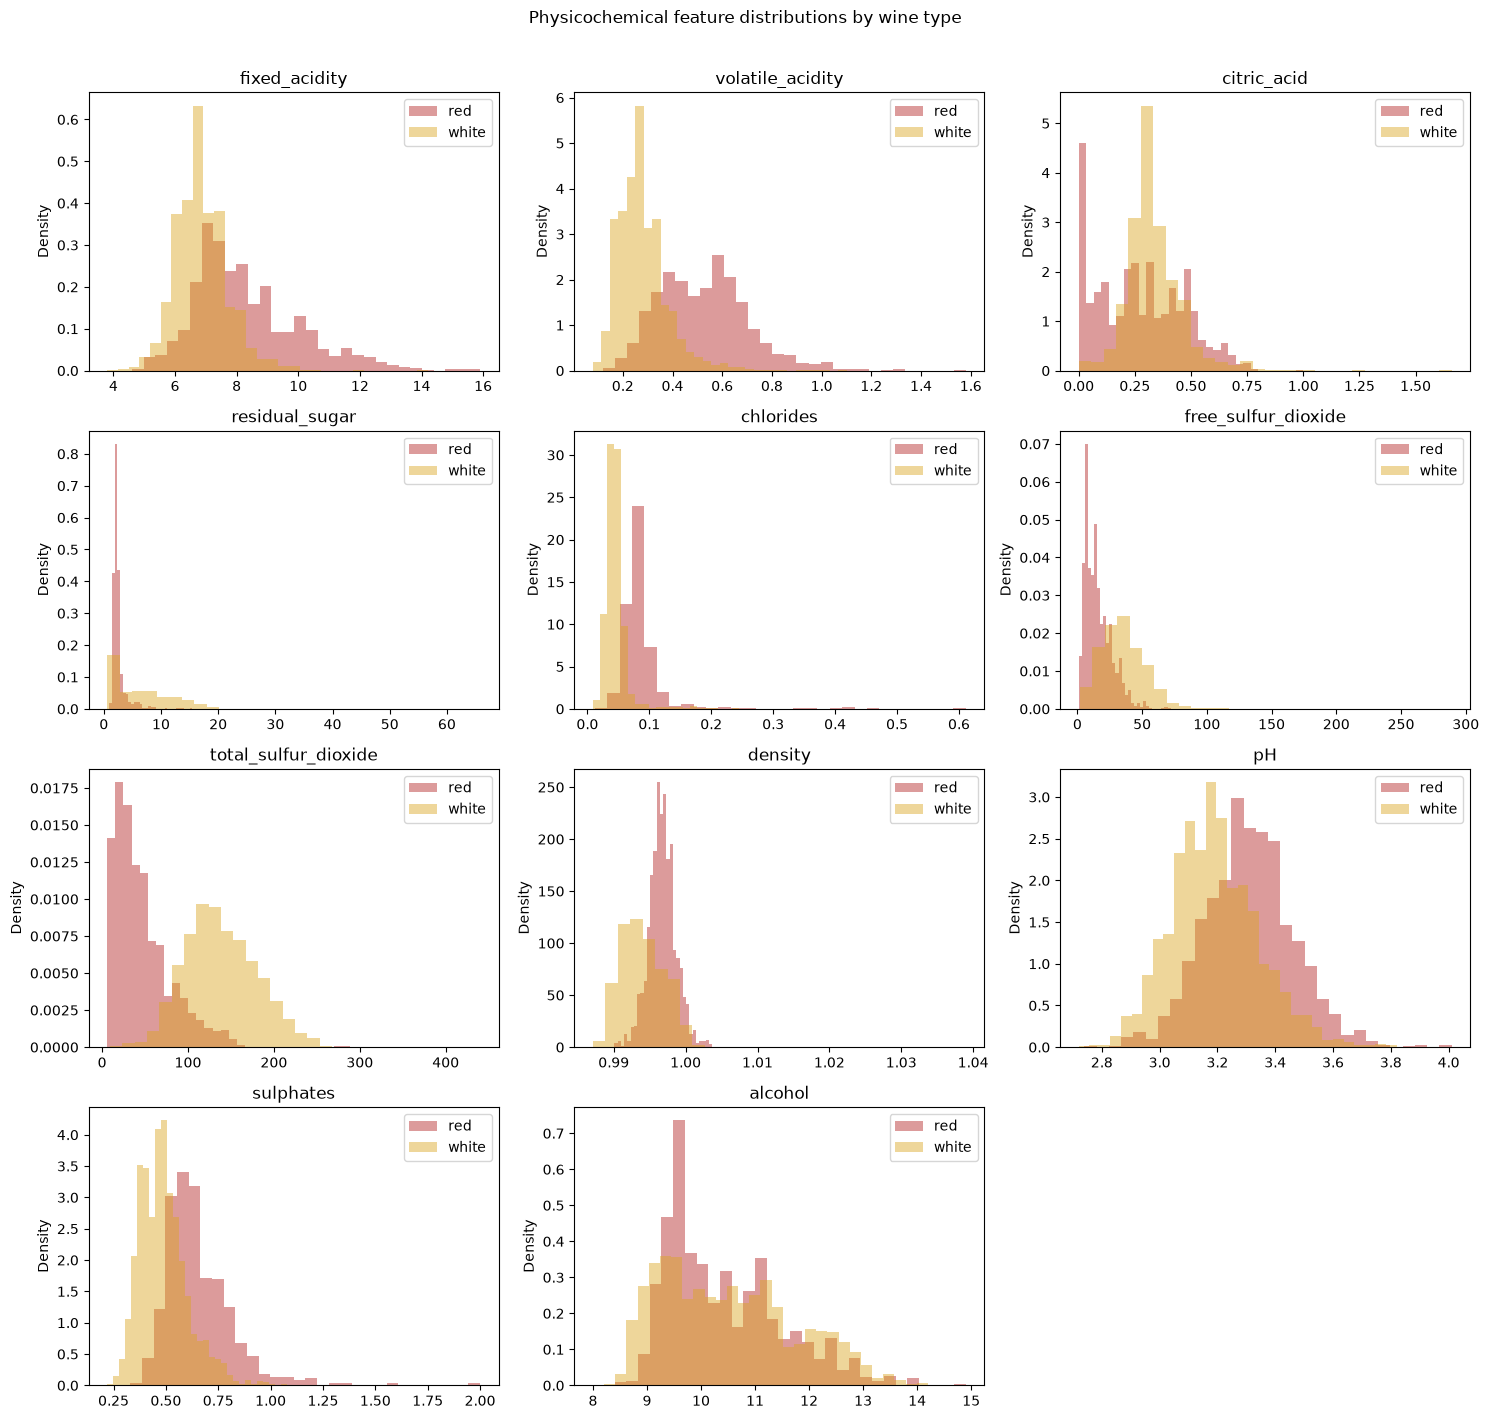

In [8]:
import matplotlib.pyplot as plt

# Compare score frequencies, using percentages in the red/white chart because group sizes differ.
quality_counts = wine_data_all[quality_col].value_counts().sort_index()
quality_pct_by_color = pd.crosstab(wine_data_all[quality_col], wine_data_all['color'], normalize='columns').reindex(columns=['red', 'white']) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
quality_counts.plot(kind='bar', ax=axes[0], color='slateblue')
axes[0].set(title='Wine quality counts', xlabel='Quality score', ylabel='Number of wines')
quality_pct_by_color.plot(kind='bar', ax=axes[1], color=['firebrick', 'goldenrod'])
axes[1].set(title='Quality distribution within each wine type', xlabel='Quality score', ylabel='Percent of wine type')
axes[1].legend(title='Wine type')
plt.tight_layout()
plt.show()

# Compare feature shapes across wine types with density histograms, so group size does not dominate.
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, feature in zip(axes.flat, feature_cols):
    for color, color_name in [('red', 'firebrick'), ('white', 'goldenrod')]:
        values = wine_data_all.loc[wine_data_all['color'].eq(color), feature]
        ax.hist(values, bins=30, density=True, alpha=0.45, color=color_name, label=color)
    ax.set_title(feature)
    ax.set_ylabel('Density')
    ax.legend()
for ax in axes.flat[len(feature_cols):]:
    ax.set_visible(False)
fig.suptitle('Physicochemical feature distributions by wine type', y=1.01)
plt.tight_layout()
plt.show()

## Step 4: Set up the evaluation split

Set aside a test set now and keep it untouched during model fitting, preprocessing choices, and feature selection. Because identical input profiles occur more than once, use a grouped split so copies of the same profile stay on the same side. Stratify approximately by quality score while forming five folds, then reserve one fold (about 20%) as the test set.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# Group identical predictor profiles (including wine color) to prevent duplicate leakage.
group_cols = feature_cols + ['color']
groups = pd.MultiIndex.from_frame(wine_data_all[group_cols]).factorize()[0]

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X_model, y_model, groups=groups))

train_data = wine_data_all.iloc[train_idx].copy()
test_data = wine_data_all.iloc[test_idx].copy()

# Keep predictors and target separate for modeling.
X_train = train_data[group_cols].copy()
y_train = train_data[quality_col].copy()
X_test = test_data[group_cols].copy()
y_test = test_data[quality_col].copy()

# Verify that each predictor profile belongs to only one partition.
train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])
assert train_groups.isdisjoint(test_groups), 'A predictor profile appears in both train and test.'
assert len(train_data) + len(test_data) == len(wine_data_all)

print(f'Train rows: {len(train_data):,} ({len(train_data) / len(wine_data_all):.1%})')
print(f'Test rows:  {len(test_data):,} ({len(test_data) / len(wine_data_all):.1%})')
print(f'Unique predictor profiles: {len(set(groups)):,}')
print('Train rows by wine type:', train_data['color'].value_counts().to_dict())
print('Test rows by wine type:', test_data['color'].value_counts().to_dict())

# Inspect class coverage only. Do not use test performance for feature selection or tuning.
split_quality_counts = pd.concat([
    y_train.value_counts().rename('train_count'),
    y_test.value_counts().rename('test_count'),
], axis=1).fillna(0).astype(int).sort_index()
print('Quality score counts in each partition:')
display(split_quality_counts)

Train rows: 5,197 (80.0%)
Test rows:  1,300 (20.0%)
Unique predictor profiles: 5,320
Train rows by wine type: {'white': 3922, 'red': 1275}
Test rows by wine type: {'white': 976, 'red': 324}
Quality score counts in each partition:


,train_count,test_count
quality,,
3,24,6
4,173,43
5,1711,427
6,2268,568
7,863,216
8,154,39
9,4,1


## Step 5: Build a simple baseline

Use the mean quality from the training set as a simple reference prediction for every test wine. This baseline does not use the physicochemical measurements or wine color. Calculate its metrics on the held-out test set once; later models should improve on this reference.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# The baseline value is learned from training labels only.
baseline_value = y_train.mean()
baseline_predictions = np.full(len(y_test), baseline_value, dtype=float)

baseline_metrics = pd.Series({
    'baseline_prediction': baseline_value,
    'MAE': mean_absolute_error(y_test, baseline_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, baseline_predictions)),
    'R2': r2_score(y_test, baseline_predictions),
}, name='mean_baseline')
print('Baseline performance on the held-out test set:')
display(baseline_metrics.to_frame('value').round(3))

# Check how the baseline error varies by wine type and actual quality score.
baseline_test_results = test_data[[quality_col, 'color']].copy()
baseline_test_results = baseline_test_results.rename(columns={quality_col: 'actual_quality'})
baseline_test_results['prediction'] = baseline_predictions
baseline_test_results['absolute_error'] = (baseline_test_results['actual_quality'] - baseline_predictions).abs()
baseline_test_results['squared_error'] = (baseline_test_results['actual_quality'] - baseline_predictions) ** 2

baseline_by_color = baseline_test_results.groupby('color').agg(
    count=('actual_quality', 'size'),
    MAE=('absolute_error', 'mean'),
    RMSE=('squared_error', lambda values: np.sqrt(values.mean())),
)
print('Baseline errors by wine type:')
display(baseline_by_color.round(3))

baseline_by_quality = baseline_test_results.groupby('actual_quality').agg(
    count=('absolute_error', 'size'),
    MAE=('absolute_error', 'mean'),
)
print('Baseline absolute error by actual quality score:')
display(baseline_by_quality.round(3))

Baseline performance on the held-out test set:


,value
baseline_prediction,5.818
MAE,0.686
RMSE,0.873
R2,-0.000


Baseline errors by wine type:


,count,MAE,RMSE
color,,,
red,324,0.667,0.825
white,976,0.692,0.889


Baseline absolute error by actual quality score:


,count,MAE
actual_quality,,
3,6,2.818
4,43,1.818
5,427,0.818
6,568,0.182
7,216,1.182
8,39,2.182
9,1,3.182


## Step 6: Compare regression models with cross-validation

Compare the mean baseline, Ridge regression, and Random Forest using only the training data. Keep identical predictor profiles together in each fold. Fit scaling and categorical encoding inside each pipeline so validation folds do not contribute to preprocessing. The test set remains untouched. There are only four score-9 wines in the training set, so use four folds and interpret performance for that rare score cautiously.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Build group-aware folds from training rows only.
cv_groups = groups[train_idx]
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
cv_splits = list(cv.split(X_train, y_train, groups=cv_groups))

# Preprocessing is fitted separately inside each training fold.
linear_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), feature_cols),
    ('color', OneHotEncoder(handle_unknown='ignore'), ['color']),
])
tree_preprocessor = ColumnTransformer([
    ('numeric', 'passthrough', feature_cols),
    ('color', OneHotEncoder(handle_unknown='ignore'), ['color']),
])

models = {
    'Mean baseline': Pipeline([
        ('preprocess', linear_preprocessor),
        ('regressor', DummyRegressor(strategy='mean')),
    ]),
    'Ridge regression': Pipeline([
        ('preprocess', linear_preprocessor),
        ('regressor', Ridge(alpha=1.0)),
    ]),
    'Random forest': Pipeline([
        ('preprocess', tree_preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1
        )),
    ]),
}

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}
cv_rows = []
fold_results = {}

for model_name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv_splits, scoring=scoring,
        return_train_score=False, n_jobs=1
    )
    mae = -scores['test_MAE']
    rmse = -scores['test_RMSE']
    r2 = scores['test_R2']
    fold_results[model_name] = pd.DataFrame({'MAE': mae, 'RMSE': rmse, 'R2': r2})
    cv_rows.append({
        'model': model_name,
        'MAE_mean': mae.mean(), 'MAE_std': mae.std(ddof=1),
        'RMSE_mean': rmse.mean(), 'RMSE_std': rmse.std(ddof=1),
        'R2_mean': r2.mean(), 'R2_std': r2.std(ddof=1),
    })

cv_summary = pd.DataFrame(cv_rows).set_index('model').sort_values('MAE_mean')
print('Grouped four-fold cross-validation results (training data only):')
display(cv_summary.round(3))
print('Per-fold scores:')
for model_name, fold_table in fold_results.items():
    print(f'\n{model_name}')
    display(fold_table.round(3))

Grouped four-fold cross-validation results (training data only):


,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
model,,,,,,
Random forest,0.533,0.011,0.691,0.016,0.373,0.030
Ridge regression,0.572,0.011,0.736,0.012,0.289,0.025
Mean baseline,0.686,0.001,0.873,0.001,-0.000,0.000


Per-fold scores:

Mean baseline


,MAE,RMSE,R2
0,0.686,0.874,-0.0
1,0.685,0.872,-0.0
2,0.686,0.874,-0.0
3,0.685,0.873,-0.0



Ridge regression


,MAE,RMSE,R2
0,0.575,0.733,0.296
1,0.585,0.753,0.254
2,0.561,0.724,0.313
3,0.567,0.734,0.293



Random forest


,MAE,RMSE,R2
0,0.526,0.677,0.399
1,0.545,0.710,0.337
2,0.522,0.679,0.396
3,0.539,0.698,0.360


## Step 7: Assess training-fold prediction errors

Generate out-of-fold predictions for the Random Forest using the grouped folds and training data from Step 6. Each row is predicted by a model that did not train on that row or its matching predictor profile. Summarize errors by actual score and wine type. The held-out test set is not used here.

Overall out-of-fold metrics on training data:


,value
MAE,0.533
RMSE,0.691
R2,0.373


Out-of-fold errors by actual quality (positive mean_error = overprediction):


,count,MAE,RMSE,mean_error
actual_quality,,,,
3,24,2.441,2.481,2.441
4,173,1.318,1.382,1.318
5,1711,0.461,0.582,0.443
6,2268,0.379,0.462,-0.111
7,863,0.685,0.792,-0.675
8,154,1.516,1.566,-1.516
9,4,2.382,2.432,-2.382


Out-of-fold errors by wine type:


,count,MAE,RMSE,mean_error
color,,,,
red,1275,0.493,0.643,-0.017
white,3922,0.546,0.706,-0.003


Counts and MAE by quality and wine type:


count    MAE
actual_quality color              
3              red        8  2.081
               white     16  2.621
4              red       41  1.275
               white    132  1.332
5              red      544  0.359
               white   1167  0.509
6              red      507  0.427
               white   1761  0.365
7              red      160  0.774
               white    703  0.665
8              red       15  1.638
               white    139  1.503
9              white      4  2.382

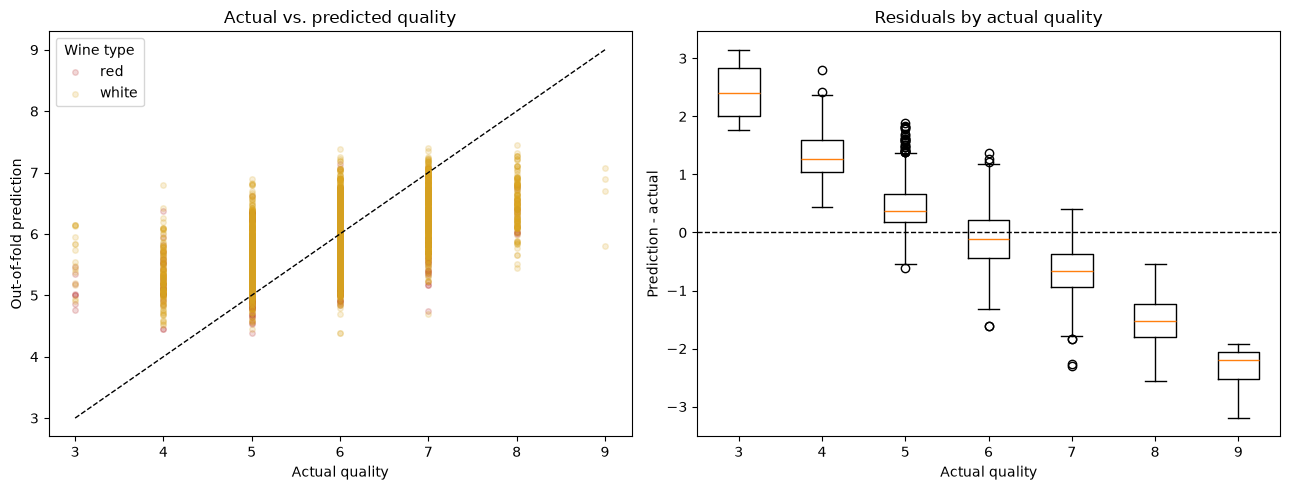

In [12]:
from sklearn.model_selection import cross_val_predict

rf_oof_predictions = cross_val_predict(
    models['Random forest'], X_train, y_train,
    cv=cv_splits, method='predict', n_jobs=1
)

rf_oof_results = train_data[[quality_col, 'color']].reset_index(drop=True).copy()
rf_oof_results = rf_oof_results.rename(columns={quality_col: 'actual_quality'})
rf_oof_results['prediction'] = rf_oof_predictions
# Positive residual means the model overpredicted quality.
rf_oof_results['residual'] = rf_oof_results['prediction'] - rf_oof_results['actual_quality']
rf_oof_results['absolute_error'] = rf_oof_results['residual'].abs()
rf_oof_results['squared_error'] = rf_oof_results['residual'] ** 2

print('Overall out-of-fold metrics on training data:')
display(pd.Series({
    'MAE': mean_absolute_error(rf_oof_results['actual_quality'], rf_oof_results['prediction']),
    'RMSE': np.sqrt(mean_squared_error(rf_oof_results['actual_quality'], rf_oof_results['prediction'])),
    'R2': r2_score(rf_oof_results['actual_quality'], rf_oof_results['prediction']),
}, name='Random Forest OOF').to_frame('value').round(3))

error_by_quality = rf_oof_results.groupby('actual_quality').agg(
    count=('actual_quality', 'size'),
    MAE=('absolute_error', 'mean'),
    RMSE=('squared_error', lambda values: np.sqrt(values.mean())),
    mean_error=('residual', 'mean'),
)
print('Out-of-fold errors by actual quality (positive mean_error = overprediction):')
display(error_by_quality.round(3))

error_by_color = rf_oof_results.groupby('color').agg(
    count=('actual_quality', 'size'),
    MAE=('absolute_error', 'mean'),
    RMSE=('squared_error', lambda values: np.sqrt(values.mean())),
    mean_error=('residual', 'mean'),
)
print('Out-of-fold errors by wine type:')
display(error_by_color.round(3))

print('Counts and MAE by quality and wine type:')
display(rf_oof_results.groupby(['actual_quality', 'color']).agg(
    count=('actual_quality', 'size'),
    MAE=('absolute_error', 'mean'),
).round(3))

# Visual checks for shrinkage toward common scores and systematic over/underprediction.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for color, point_color in [('red', 'firebrick'), ('white', 'goldenrod')]:
    subset = rf_oof_results.loc[rf_oof_results['color'].eq(color)]
    axes[0].scatter(subset['actual_quality'], subset['prediction'], alpha=0.18, s=16, color=point_color, label=color)
axes[0].plot([3, 9], [3, 9], linestyle='--', color='black', linewidth=1)
axes[0].set(xlabel='Actual quality', ylabel='Out-of-fold prediction', title='Actual vs. predicted quality')
axes[0].legend(title='Wine type')
scores = error_by_quality.index.tolist()
residuals_by_score = [rf_oof_results.loc[rf_oof_results['actual_quality'].eq(score), 'residual'] for score in scores]
axes[1].boxplot(residuals_by_score)
axes[1].set_xticks(range(1, len(scores) + 1))
axes[1].set_xticklabels(scores)
axes[1].axhline(0, linestyle='--', color='black', linewidth=1)
axes[1].set(xlabel='Actual quality', ylabel='Prediction - actual', title='Residuals by actual quality')
plt.tight_layout()
plt.show()

## Step 8: Tune the Random Forest

The Random Forest led the model comparison, so try a small randomized search over tree depth, feature subsampling, leaf size, bootstrap sample size, and number of trees. Select settings by grouped cross-validation MAE on the training data only. The best CV score is used to choose settings; it is not a final unbiased performance estimate. Keep the test set untouched for the final evaluation.

In [13]:
from sklearn.model_selection import RandomizedSearchCV

rf_parameter_options = {
    'regressor__n_estimators': [200, 400],
    'regressor__max_depth': [None, 12, 20],
    'regressor__max_features': [0.5, 0.8, 1.0],
    'regressor__min_samples_leaf': [1, 2, 4, 8],
    'regressor__max_samples': [0.7, 0.9, 1.0],
}

rf_search = RandomizedSearchCV(
    estimator=models['Random forest'],
    param_distributions=rf_parameter_options,
    n_iter=18,
    scoring='neg_mean_absolute_error',
    cv=cv_splits,
    random_state=42,
    n_jobs=1,
    refit=True,
    return_train_score=False,
)
rf_search.fit(X_train, y_train)
tuned_rf_model = rf_search.best_estimator_

print('Best parameters selected by grouped training CV:')
display(pd.Series(rf_search.best_params_, name='value').to_frame())
print(f'Best grouped CV MAE: {-rf_search.best_score_:.3f}')
print(f'Untuned Random Forest grouped CV MAE: {cv_summary.loc["Random forest", "MAE_mean"]:.3f}')

tuning_results = pd.DataFrame(rf_search.cv_results_).copy()
tuning_results['CV_MAE'] = -tuning_results['mean_test_score']
top_tuning_results = tuning_results.sort_values('CV_MAE').head(10)
parameter_columns = [
    'CV_MAE', 'std_test_score',
    'param_regressor__n_estimators', 'param_regressor__max_depth',
    'param_regressor__max_features', 'param_regressor__min_samples_leaf',
    'param_regressor__max_samples',
]
print('Top parameter combinations (lower CV_MAE is better):')
display(top_tuning_results[parameter_columns].rename(columns={'std_test_score': 'MAE_std'}).round(3))

Best parameters selected by grouped training CV:


,value
regressor__n_estimators,400.0
regressor__min_samples_leaf,1.0
regressor__max_samples,0.9
regressor__max_features,0.5
regressor__max_depth,NaN


Best grouped CV MAE: 0.528
Untuned Random Forest grouped CV MAE: 0.533
Top parameter combinations (lower CV_MAE is better):


,CV_MAE,MAE_std,param_regressor__n_estimators,param_regressor__max_depth,param_regressor__max_features,param_regressor__min_samples_leaf,param_regressor__max_samples
13,0.528,0.010,400,None,0.5,1,0.9
17,0.529,0.009,200,None,0.5,2,1.0
3,0.531,0.008,400,20,0.8,1,0.9
15,0.532,0.008,200,20,0.8,1,0.9
14,0.532,0.010,400,None,1.0,2,1.0
7,0.533,0.008,400,12,0.5,1,0.7
0,0.533,0.008,400,20,1.0,1,0.9
16,0.534,0.008,200,20,0.8,4,0.7
1,0.535,0.010,400,20,1.0,4,1.0
8,0.535,0.009,400,20,1.0,4,0.9


## Step 9: Compare feature-selection options

Now compare the tuned Random Forest using all transformed predictors with univariate `SelectKBest` feature selection. The selector is part of the pipeline, so it is refit using each CV training fold and cannot see that fold's validation rows. Scores are grouped cross-validation results on the training set; the held-out test set remains untouched. `k` counts transformed columns, including the two one-hot columns for wine color.

In [14]:
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_regression

# Include the all-feature model as a control. Selection is fit inside every CV fold.
# The color column becomes two one-hot columns, so there are 13 transformed predictors.
feature_counts = [5, 8, 11, 'all']
feature_selection_rows = []
feature_selection_models = {}

for k in feature_counts:
    selection_pipeline = Pipeline([
        ('preprocess', clone(tuned_rf_model.named_steps['preprocess'])),
        ('select', SelectKBest(score_func=f_regression, k=k)),
        ('regressor', clone(tuned_rf_model.named_steps['regressor'])),
    ])
    selection_scores = cross_validate(
        selection_pipeline, X_train, y_train,
        cv=cv_splits, scoring=scoring,
        return_train_score=False, n_jobs=1,
    )
    mae = -selection_scores['test_MAE']
    rmse = -selection_scores['test_RMSE']
    r2 = selection_scores['test_R2']
    label = 'All (13)' if k == 'all' else f'Top {k}'
    feature_selection_models[label] = selection_pipeline
    feature_selection_rows.append({
        'features': label,
        'MAE_mean': mae.mean(), 'MAE_std': mae.std(ddof=1),
        'RMSE_mean': rmse.mean(), 'RMSE_std': rmse.std(ddof=1),
        'R2_mean': r2.mean(), 'R2_std': r2.std(ddof=1),
    })

feature_selection_summary = (
    pd.DataFrame(feature_selection_rows)
    .set_index('features')
    .sort_values('MAE_mean')
)
print('Grouped CV comparison on training data only (lower MAE is better):')
display(feature_selection_summary.round(3))
print(f"Tuned all-feature search CV MAE: {-rf_search.best_score_:.3f}")

# Refit the winning feature-count pipeline on training rows to inspect its columns.
# This does not use the test set or change the CV scores above.
best_feature_label = feature_selection_summary.index[0]
best_feature_pipeline = feature_selection_models[best_feature_label]
best_feature_pipeline.fit(X_train, y_train)
transformed_names = best_feature_pipeline.named_steps['preprocess'].get_feature_names_out()
selected_names = transformed_names[best_feature_pipeline.named_steps['select'].get_support()]
print(f'Selected transformed features for {best_feature_label}:')
print(list(selected_names))

Grouped CV comparison on training data only (lower MAE is better):


,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
features,,,,,,
All (13),0.528,0.012,0.684,0.016,0.386,0.030
Top 11,0.536,0.006,0.693,0.009,0.369,0.016
Top 8,0.552,0.007,0.715,0.011,0.328,0.022
Top 5,0.573,0.008,0.745,0.008,0.273,0.016


Tuned all-feature search CV MAE: 0.528
Selected transformed features for All (13):
['numeric__fixed_acidity', 'numeric__volatile_acidity', 'numeric__citric_acid', 'numeric__residual_sugar', 'numeric__chlorides', 'numeric__free_sulfur_dioxide', 'numeric__total_sulfur_dioxide', 'numeric__density', 'numeric__pH', 'numeric__sulphates', 'numeric__alcohol', 'color__color_red', 'color__color_white']


## Step 10: Evaluate the selected model on the held-out test set

Use the tuned Random Forest with all 13 transformed predictors, selected in Step 9, for one final evaluation on the test set. `RandomizedSearchCV` refit its best model on all training rows, so this evaluation does not fit anything on the test data. Compare test metrics with the mean baseline and inspect errors by wine type and actual quality. Do not use these test results to make further model choices.

In [15]:
# The best estimator was refit on all training rows by RandomizedSearchCV.
# Predict the held-out test rows once; do not refit on them.
final_model = rf_search.best_estimator_
final_test_predictions = final_model.predict(X_test)

final_model_metrics = {
    'MAE': mean_absolute_error(y_test, final_test_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, final_test_predictions)),
    'R2': r2_score(y_test, final_test_predictions),
}
baseline_test_metrics = {
    'MAE': mean_absolute_error(y_test, baseline_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, baseline_predictions)),
    'R2': r2_score(y_test, baseline_predictions),
}
test_metrics_comparison = pd.DataFrame({
    'Mean baseline': baseline_test_metrics,
    'Tuned Random Forest (all features)': final_model_metrics,
}).T
print('Final comparison on the held-out test set:')
display(test_metrics_comparison.round(3))

# Inspect whether errors differ by wine color and actual quality score.
final_test_results = test_data[[quality_col, 'color']].copy()
final_test_results = final_test_results.rename(columns={quality_col: 'actual_quality'})
final_test_results['prediction'] = final_test_predictions
final_test_results['absolute_error'] = (
    final_test_results['actual_quality'] - final_test_results['prediction']
).abs()
final_test_results['squared_error'] = (
    final_test_results['actual_quality'] - final_test_results['prediction']
) ** 2

print('Test errors by wine type:')
display(final_test_results.groupby('color').agg(
    count=('actual_quality', 'size'),
    MAE=('absolute_error', 'mean'),
    RMSE=('squared_error', lambda values: np.sqrt(values.mean())),
).round(3))

print('Test errors by actual quality score (small groups are uncertain):')
display(final_test_results.groupby('actual_quality').agg(
    count=('actual_quality', 'size'),
    MAE=('absolute_error', 'mean'),
    RMSE=('squared_error', lambda values: np.sqrt(values.mean())),
).round(3))

Final comparison on the held-out test set:


,MAE,RMSE,R2
Mean baseline,0.686,0.873,-0.000
Tuned Random Forest (all features),0.518,0.673,0.405


Test errors by wine type:


,count,MAE,RMSE
color,,,
red,324,0.472,0.617
white,976,0.533,0.691


Test errors by actual quality score (small groups are uncertain):


,count,MAE,RMSE
actual_quality,,,
3,6,2.284,2.338
4,43,1.337,1.387
5,427,0.467,0.570
6,568,0.358,0.439
7,216,0.645,0.765
8,39,1.483,1.551
9,1,2.335,2.335


## Step 11: Summarize the final evaluation

On the held-out test set, the tuned Random Forest using all 13 transformed predictors achieved MAE **0.518**, RMSE **0.673**, and R² **0.405**. The mean baseline scored MAE **0.686**, RMSE **0.873**, and R² approximately **0**. The tuned model's test MAE is about 24% lower than the baseline's. Its test MAE is also close to the grouped training-CV result (0.528), suggesting similar performance on this split.

Errors were lowest for common quality scores 5 and 6 (MAE 0.467 and 0.358) and considerably higher for scores 3 and 8 (MAE 2.284 and 1.483). Score 9 has just one test example, so its error is not a reliable estimate for that score. Red wines had MAE 0.472 and white wines 0.533; these pooled figures can reflect differing score distributions and should not be read as a controlled comparison.

The model improves substantially over the simple baseline, but it predicts typical wines much better than rare extremes. Treat the test result as the final estimate for this split; do not use it to choose more features or tune settings. If continuing the project, use training-only out-of-fold analysis to examine feature importance or investigate rare-score cases, and evaluate any newly chosen modeling approach with a fresh evaluation design.